# Experiment 4 — Option 2 on `014845` only

Repetition HMM on phrase distances. Eval spectrogram with theme segments and `C` boundaries (cyan).

```bash
python -m analysis.song_hmm.exp4.run_014845
```

Kernel: **Python (panMP / ensemble)**.

In [1]:
import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

from analysis.song_hmm.exp4.paths import WORK, GPL_014845
from analysis.song_hmm.exp4.spectrogram import stitch_gpl, plot_themes_on_spectrogram
from analysis.song_hmm.exp4.sequence import load_sequences
from analysis.song_hmm.exp4.phrases import cut_phrases, phrase_feature_rows
from analysis.dict_learning.code.cli import load_windows

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

RES = WORK / "results" / "014845"
summary = json.loads((RES / "summary.json").read_text())
block = json.loads((RES / "eval.json").read_text())["option2"]
themes, bounds = block["themes"], block["boundaries"]
n = len(load_windows(GPL_014845, None, 0)); n_train = n // 2
t_mid = summary["t_mid_s"]

In [2]:
rows = [{"model": m, **sc} for m, sc in summary["scores"].items()]
display(pd.DataFrame(rows).set_index("model")[["f1@10s", "recall@10s", "precision@10s", "false_alarms_per_h", "n_pred"]].round(3))
print("option2 qualitative:", summary["qualitative"])

,f1@10s,recall@10s,precision@10s,false_alarms_per_h,n_pred
model,,,,,
option1_pair,0.000,0.000,0.000,0.000,0.0
option1_full,0.105,0.333,0.062,93.000,32.0
option2,0.279,1.000,0.162,99.414,37.0
B1,1.000,1.000,1.000,0.000,6.0
B2,0.102,1.000,0.054,339.932,112.0


option2 qualitative: {'option1_pair_n_themes': 2, 'option1_full_n_themes': 40, 'option2_n_themes': 38, 'option2_median_theme_s': 12.49200000000019, 'option2_frac_themes_lt_30s': 0.7631578947368421, 'train_n_tokens': 454, 'eval_n_tokens': 458}


38 segments, 37 boundaries


,theme,t0,t1,n_phrases,dur_s
0,seg0,1125.672,1141.128,3,15.456
1,seg1,1143.720,1144.872,1,1.152
2,seg2,1154.664,1163.688,2,9.024
3,seg3,1172.904,1199.784,3,26.880
4,seg4,1202.976,1324.536,7,121.560
5,seg5,1333.272,1362.000,4,28.728
6,seg6,1365.072,1373.712,3,8.640
7,seg7,1377.456,1443.720,8,66.264
8,seg8,1445.832,1446.792,1,0.960
9,seg9,1448.712,1458.408,3,9.696


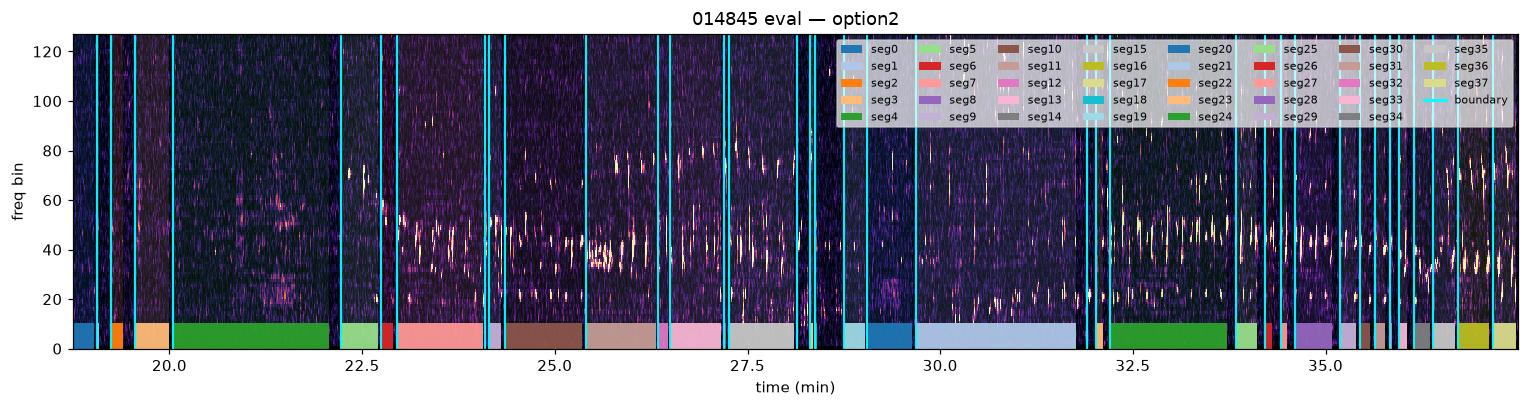

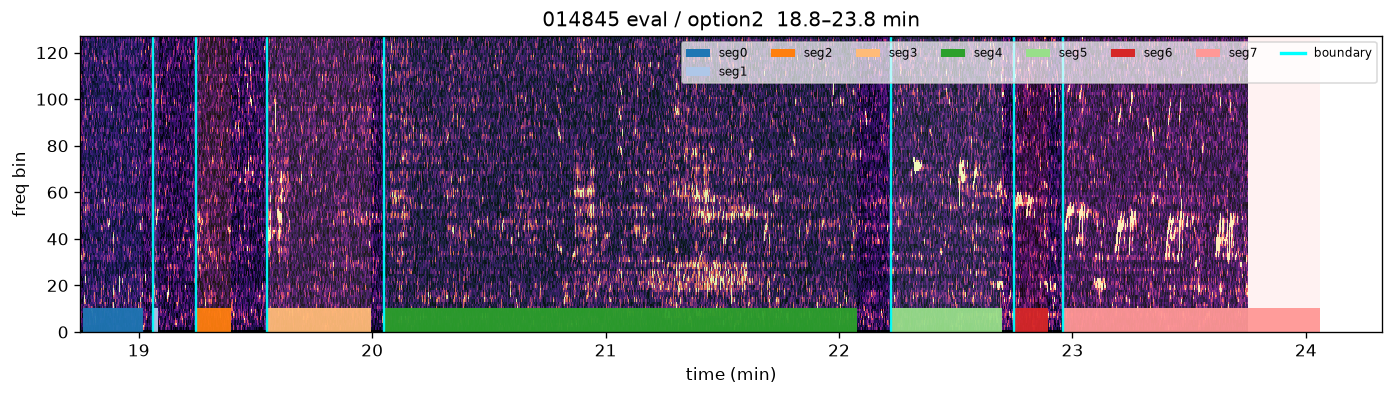

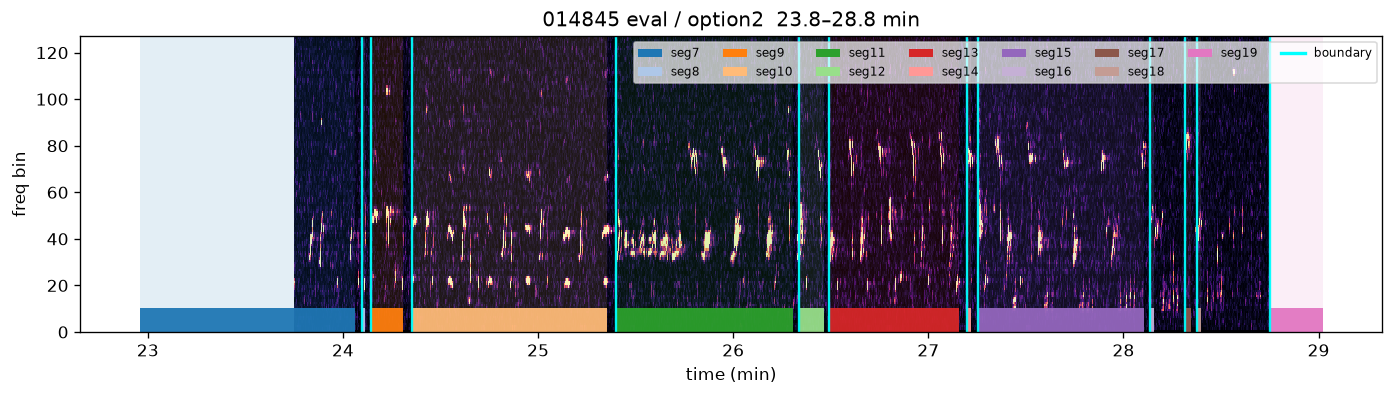

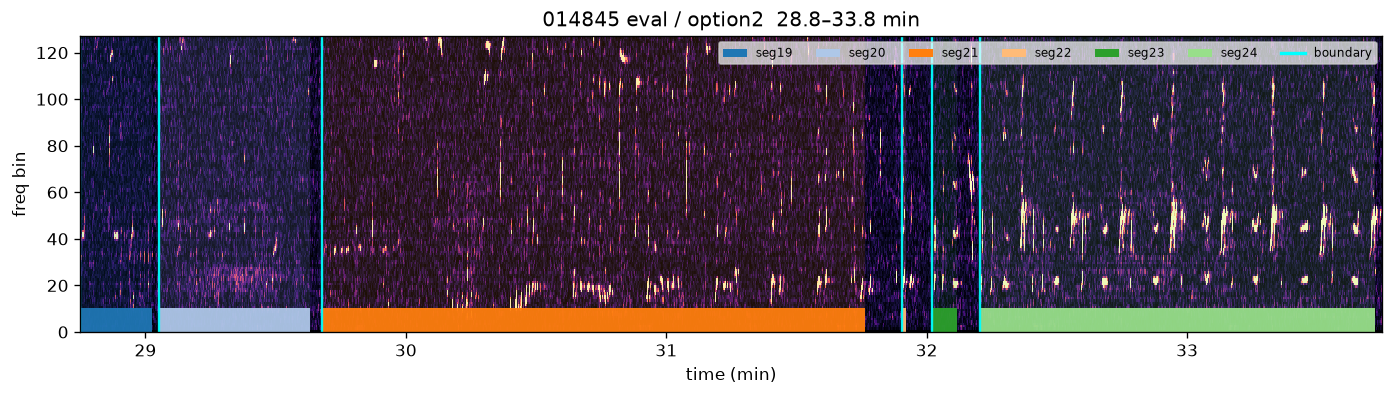

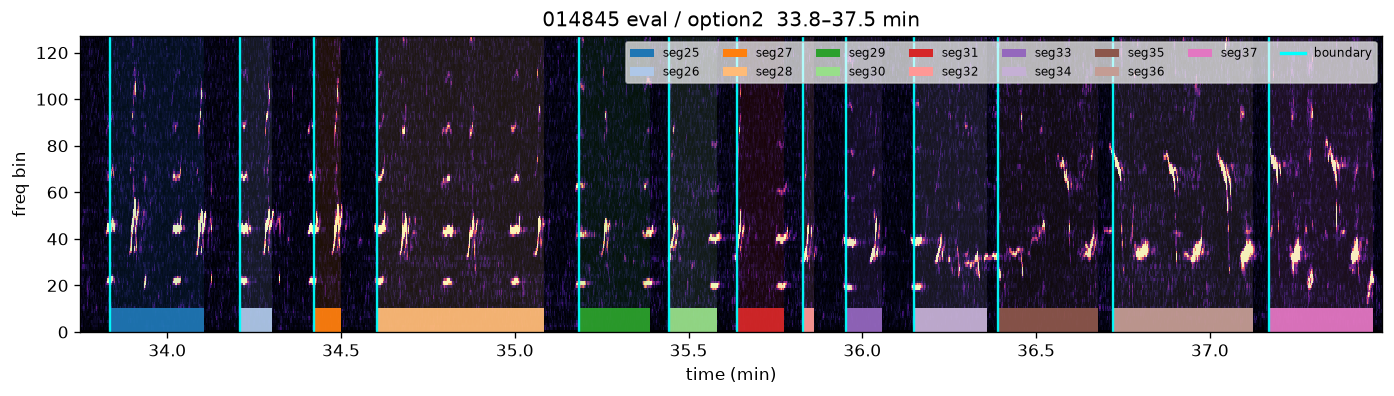

In [3]:
print(f"{len(themes)} segments, {len(bounds)} boundaries")
tdf = pd.DataFrame(themes)
if len(tdf):
    tdf["dur_s"] = tdf["t1"] - tdf["t0"]
    display(tdf)
spec, t0, t1, _ = stitch_gpl(GPL_014845, window_offset=n_train, n_windows=n - n_train)
fig, ax = plt.subplots(figsize=(14, 3.8))
plot_themes_on_spectrogram(spec, t0, t1, themes, bounds, title="014845 eval — option2", ax=ax)
plt.tight_layout(); plt.show()
for p in sorted((WORK / "figures" / "014845" / "option2").glob("slice_*.png")):
    display(Image(filename=str(p)))

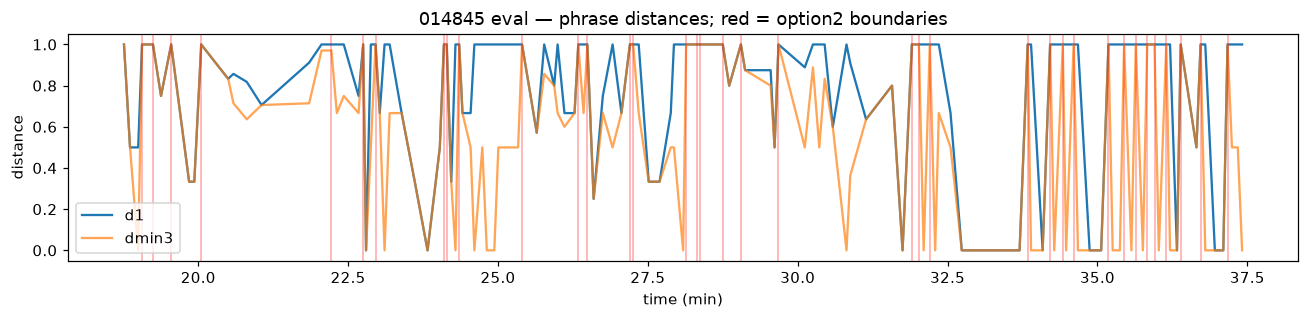

In [4]:
sessions, _ = load_sequences(WORK / "sequences" / "014845.json")
rows = []
for s in sessions:
    ph = cut_phrases(s)
    for p, f in zip(ph, phrase_feature_rows(ph)):
        if p.t0 < t_mid:
            continue
        rows.append({"t0": p.t0, "d1": f.d1, "dmin3": f.dmin3})
feat = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(feat["t0"] / 60, feat["d1"], label="d1")
ax.plot(feat["t0"] / 60, feat["dmin3"], label="dmin3", alpha=0.7)
for b in bounds:
    ax.axvline(b / 60, color="r", alpha=0.35, lw=1)
ax.set_xlabel("time (min)"); ax.set_ylabel("distance"); ax.legend()
ax.set_title("014845 eval — phrase distances; red = option2 boundaries")
plt.tight_layout(); plt.show()